Python Data Cleaning and Visualization - 2026-10-13 - Tapses1661

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the Excel dataset
df = pd.read_excel("AirBnBSummary_v2.xlsx")

# Display the first few rows
df.head()

,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
0,7909479,41706311,David,Downtown,Entire home/apt,107.0,30,27,365.0,NaN
1,15966488,103700433,Erin,Downtown,Entire home/apt,100.0,1,250,74.0,NaN
2,19859814,103700433,Erin,Downtown,Entire home/apt,100.0,1,309,79.0,NaN
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,NaN
4,21712505,103700433,Erin,Downtown,Entire home/apt,100.0,1,178,68.0,NaN


In [2]:
# Step 1: Remove duplicate rows

print("Duplicate rows before cleaning:")
display(df[df.duplicated()])

# Remove duplicates
df_cleaned = df.drop_duplicates().copy()

print("Duplicate rows after cleaning:")
display(df_cleaned[df_cleaned.duplicated()])

Duplicate rows before cleaning:


,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
1775,27252097,205256572,Stephanie,West Olentangy,Entire home/apt,296.0,1,164,167.0,NaN
1776,28640445,181661236,Chris,West Olentangy,Entire home/apt,105.0,2,280,170.0,NaN
1777,620815000000000000,453019578,Devon,West Olentangy,Entire home/apt,99.0,15,3,65.0,NaN
1778,620918000000000000,453019578,Devon,West Olentangy,Entire home/apt,90.0,30,1,0.0,NaN


Duplicate rows after cleaning:


,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>


In [3]:
# Step 2: Correct "Private room" to "Private Room"

print("Before correction:")
print(df_cleaned['room_type'].value_counts())

df_cleaned['room_type'] = df_cleaned['room_type'].replace(
    'Private room',
    'Private Room'
)

print("\nAfter correction:")
print(df_cleaned['room_type'].value_counts())

Before correction:
room_type
Entire home/apt    1535
Private room        240
Name: count, dtype: int64

After correction:
room_type
Entire home/apt    1535
Private Room        240
Name: count, dtype: int64


In [4]:
# Step 3: Fill missing numeric values with the median

print("Missing values before cleaning:")
print(df_cleaned.isnull().sum())

# Fill missing values in numeric columns with each column's median
numeric_columns = df_cleaned.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df_cleaned[column] = df_cleaned[column].fillna(
        df_cleaned[column].median()
    )

print("\nMissing values after cleaning:")
print(df_cleaned.isnull().sum())

Missing values before cleaning:
id                      0
host_id                 0
host_name               0
neighbourhood           0
room_type               0
price                   4
minimum_nights          0
number_of_reviews       0
availability_365        5
<StudentID>          1775
dtype: int64

Missing values after cleaning:
id                      0
host_id                 0
host_name               0
neighbourhood           0
room_type               0
price                   0
minimum_nights          0
number_of_reviews       0
availability_365        0
<StudentID>          1775
dtype: int64


In [5]:
# Add StudentID to every row
df_cleaned['<StudentID>'] = "Tapses1661"

print(df_cleaned['<StudentID>'].value_counts())

<StudentID>
Tapses1661    1775
Name: count, dtype: int64


In [6]:
# Step 4: Remove outliers using the IQR method

outlier_columns = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'availability_365'
]

print("Rows before removing outliers:", len(df_cleaned))

# Start with all rows included
keep_rows = pd.Series(True, index=df_cleaned.index)

for column in outlier_columns:
    Q1 = df_cleaned[column].quantile(0.25)
    Q3 = df_cleaned[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df_cleaned[column] < lower_bound) |
        (df_cleaned[column] > upper_bound)
    )

    print(f"{column}: {outliers.sum()} outliers")

    keep_rows &= ~outliers

# Keep only rows that are not outliers
df_cleaned = df_cleaned[keep_rows].copy()

print("\nRows after removing outliers:", len(df_cleaned))

Rows before removing outliers: 1775
price: 118 outliers
minimum_nights: 296 outliers
number_of_reviews: 173 outliers
availability_365: 0 outliers

Rows after removing outliers: 1205


In [7]:
# Step 5: Save the cleaned dataset

output_file = "AirBnBSummary_v2_Python_Cleaned.xlsx"

df_cleaned.to_excel(output_file, index=False)

print("Cleaned dataset saved successfully as:")
print(output_file)

Cleaned dataset saved successfully as:
AirBnBSummary_v2_Python_Cleaned.xlsx


In [8]:
# Step 6: Calculate descriptive statistics

total_count = len(df_cleaned)
minimum_price = df_cleaned['price'].min()
maximum_price = df_cleaned['price'].max()
mean_price = df_cleaned['price'].mean()
median_reviews = df_cleaned['number_of_reviews'].median()
mode_minimum_nights = df_cleaned['minimum_nights'].mode().iloc[0]
std_price = df_cleaned['price'].std()
correlation_price_availability = df_cleaned['price'].corr(
    df_cleaned['availability_365']
)

print("Total count of listings:", total_count)
print("Minimum price:", minimum_price)
print("Maximum price:", maximum_price)
print("Mean price of listings:", mean_price)
print("Median number of reviews:", median_reviews)
print("Mode of minimum nights:", mode_minimum_nights)
print("Standard deviation of price:", std_price)
print("Correlation between price and availability_365:",
      correlation_price_availability)

Total count of listings: 1205
Minimum price: 32.0
Maximum price: 308.0
Mean price of listings: 132.18008298755186
Median number of reviews: 20.0
Mode of minimum nights: 1
Standard deviation of price: 62.533791011464615
Correlation between price and availability_365: 0.09281345709052656


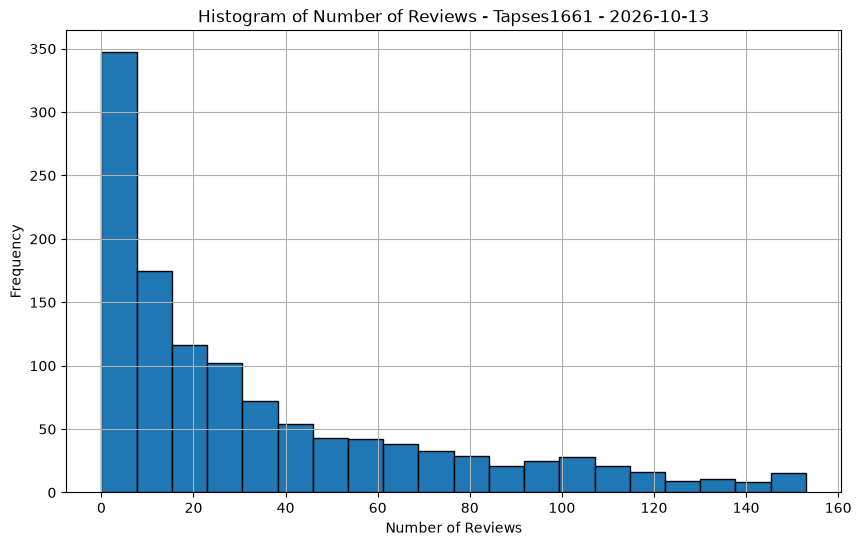

In [9]:
# Step 7: Histogram of number_of_reviews

plt.figure(figsize=(10, 6))

plt.hist(
    df_cleaned['number_of_reviews'],
    bins=20,
    edgecolor='black'
)

plt.title(
    'Histogram of Number of Reviews - Tapses1661 - 2026-10-13'
)

plt.xlabel('Number of Reviews')
plt.ylabel('Frequency')

plt.grid(True)

plt.show()

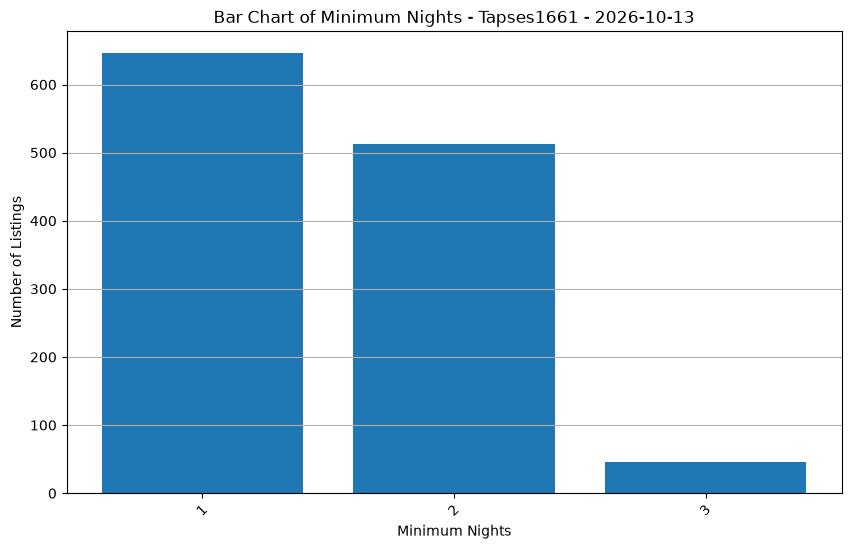

In [10]:
# Step 8: Bar chart of minimum_nights

minimum_nights_counts = (
    df_cleaned['minimum_nights']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

plt.bar(
    minimum_nights_counts.index.astype(str),
    minimum_nights_counts.values
)

plt.title(
    'Bar Chart of Minimum Nights - Tapses1661 - 2026-10-13'
)

plt.xlabel('Minimum Nights')
plt.ylabel('Number of Listings')

plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()

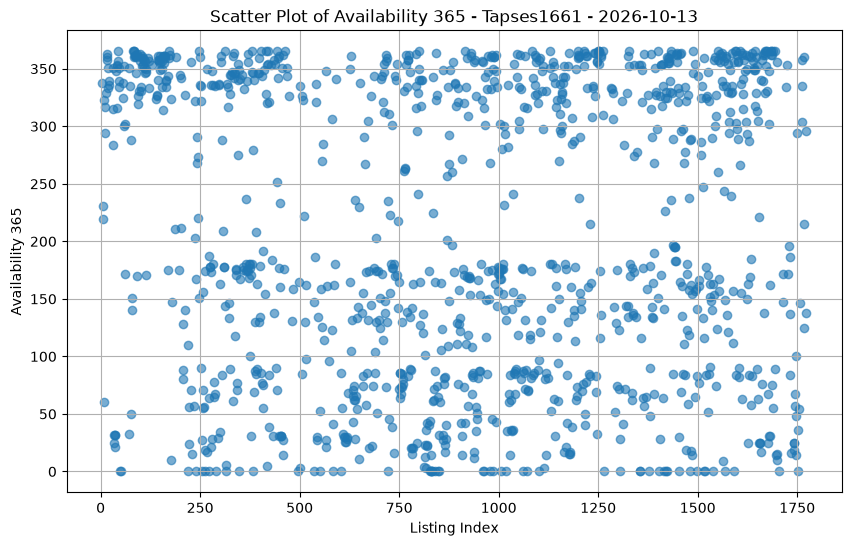

In [11]:
# Step 9: Scatter plot of availability_365

plt.figure(figsize=(10, 6))

plt.scatter(
    df_cleaned.index,
    df_cleaned['availability_365'],
    alpha=0.6
)

plt.title(
    'Scatter Plot of Availability 365 - Tapses1661 - 2026-10-13'
)

plt.xlabel('Listing Index')
plt.ylabel('Availability 365')

plt.grid(True)

plt.show()

In [ ]:
# Step 10: Correlation heat map

import seaborn as sns

correlation_columns = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'availability_365'
]

correlation_matrix = df_cleaned[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title(
    'Correlation Heat Map - Tapses1661 - 2026-10-13'
)

plt.show()

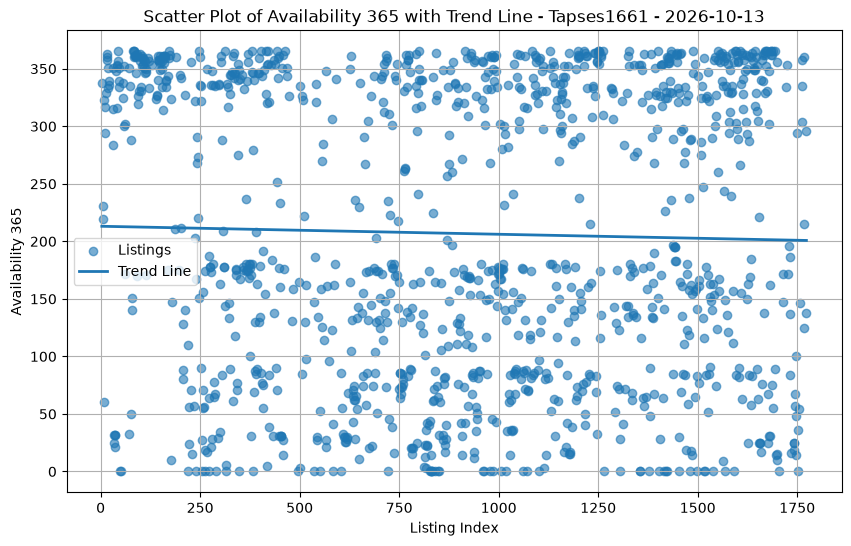

In [13]:
# Scatter plot with trend line for availability_365

x = df_cleaned.index
y = df_cleaned['availability_365']

trend = np.polyfit(x, y, 1)
trend_line = np.poly1d(trend)

plt.figure(figsize=(10, 6))

plt.scatter(x, y, alpha=0.6, label='Listings')
plt.plot(x, trend_line(x), linewidth=2, label='Trend Line')

plt.title(
    'Scatter Plot of Availability 365 with Trend Line - '
    'Tapses1661 - 2026-10-13'
)

plt.xlabel('Listing Index')
plt.ylabel('Availability 365')
plt.legend()
plt.grid(True)

plt.show()